In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, NullFormatter

import scipy
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.special import erf

import importlib

import delayscan
importlib.reload(delayscan)
importlib.reload(delayscan.TRclasses)

from delayscan import analysis as tran
from delayscan import TRclasses as tr
from delayscan.TRclasses import reduceBins


In [4]:
# Load default mpl style
plt.style.use("assets/TRPES.mplstyle")

#Other standard figure widths
fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

#Dedault mpl colour tablet
colors = list(mcolors.TABLEAU_COLORS)

In [5]:
CROSS_CORRELATION = 0.320 #cross-corrleation with 250 & 267
SIGMA = CROSS_CORRELATION / 2.355 
SIGMA

0.13588110403397027

In [6]:
# create DelayScanSet instance
scanSet = tr.DelayScanSet()
#Load data
load_data = np.loadtxt("data/out/RebinnedExperimentalData.csv",delimiter=',')
#Populate scanSet
scanSet.delays = load_data[1:,0]
scanSet.energies_rebinned = load_data[0,1:]
scanSet.subtracted_rebinned = load_data[1:,1:]


### Find accurate t0

Determine t0 by fitting the total counts with a sum of exponential (here are 1 and 2) and find the value of t0. Sigma = cross-correlation/2.335 can be set to a specific value or floated. 

In [7]:
delays = scanSet.delays
#Integrate spectra to get total counts at each delay
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

fit_func = lambda x,A1,tau1,t0: tran.monoexponential_witht0(x,A1,tau1,t0,SIGMA)

params,pcov=curve_fit(fit_func,delays,trace,
                  p0=[0.8,1.8,0])
perr = np.sqrt(np.diag(pcov))

print(params)

t0 = params[-1]
# Save t0 to scanSet
scanSet.t0 = params[-1]


[ 0.55653385  2.83061786 -0.19604916]


A1, tau1, t0
[0.5565, 2.8306, -0.196]
[0.0029, 0.046, 0.0032]


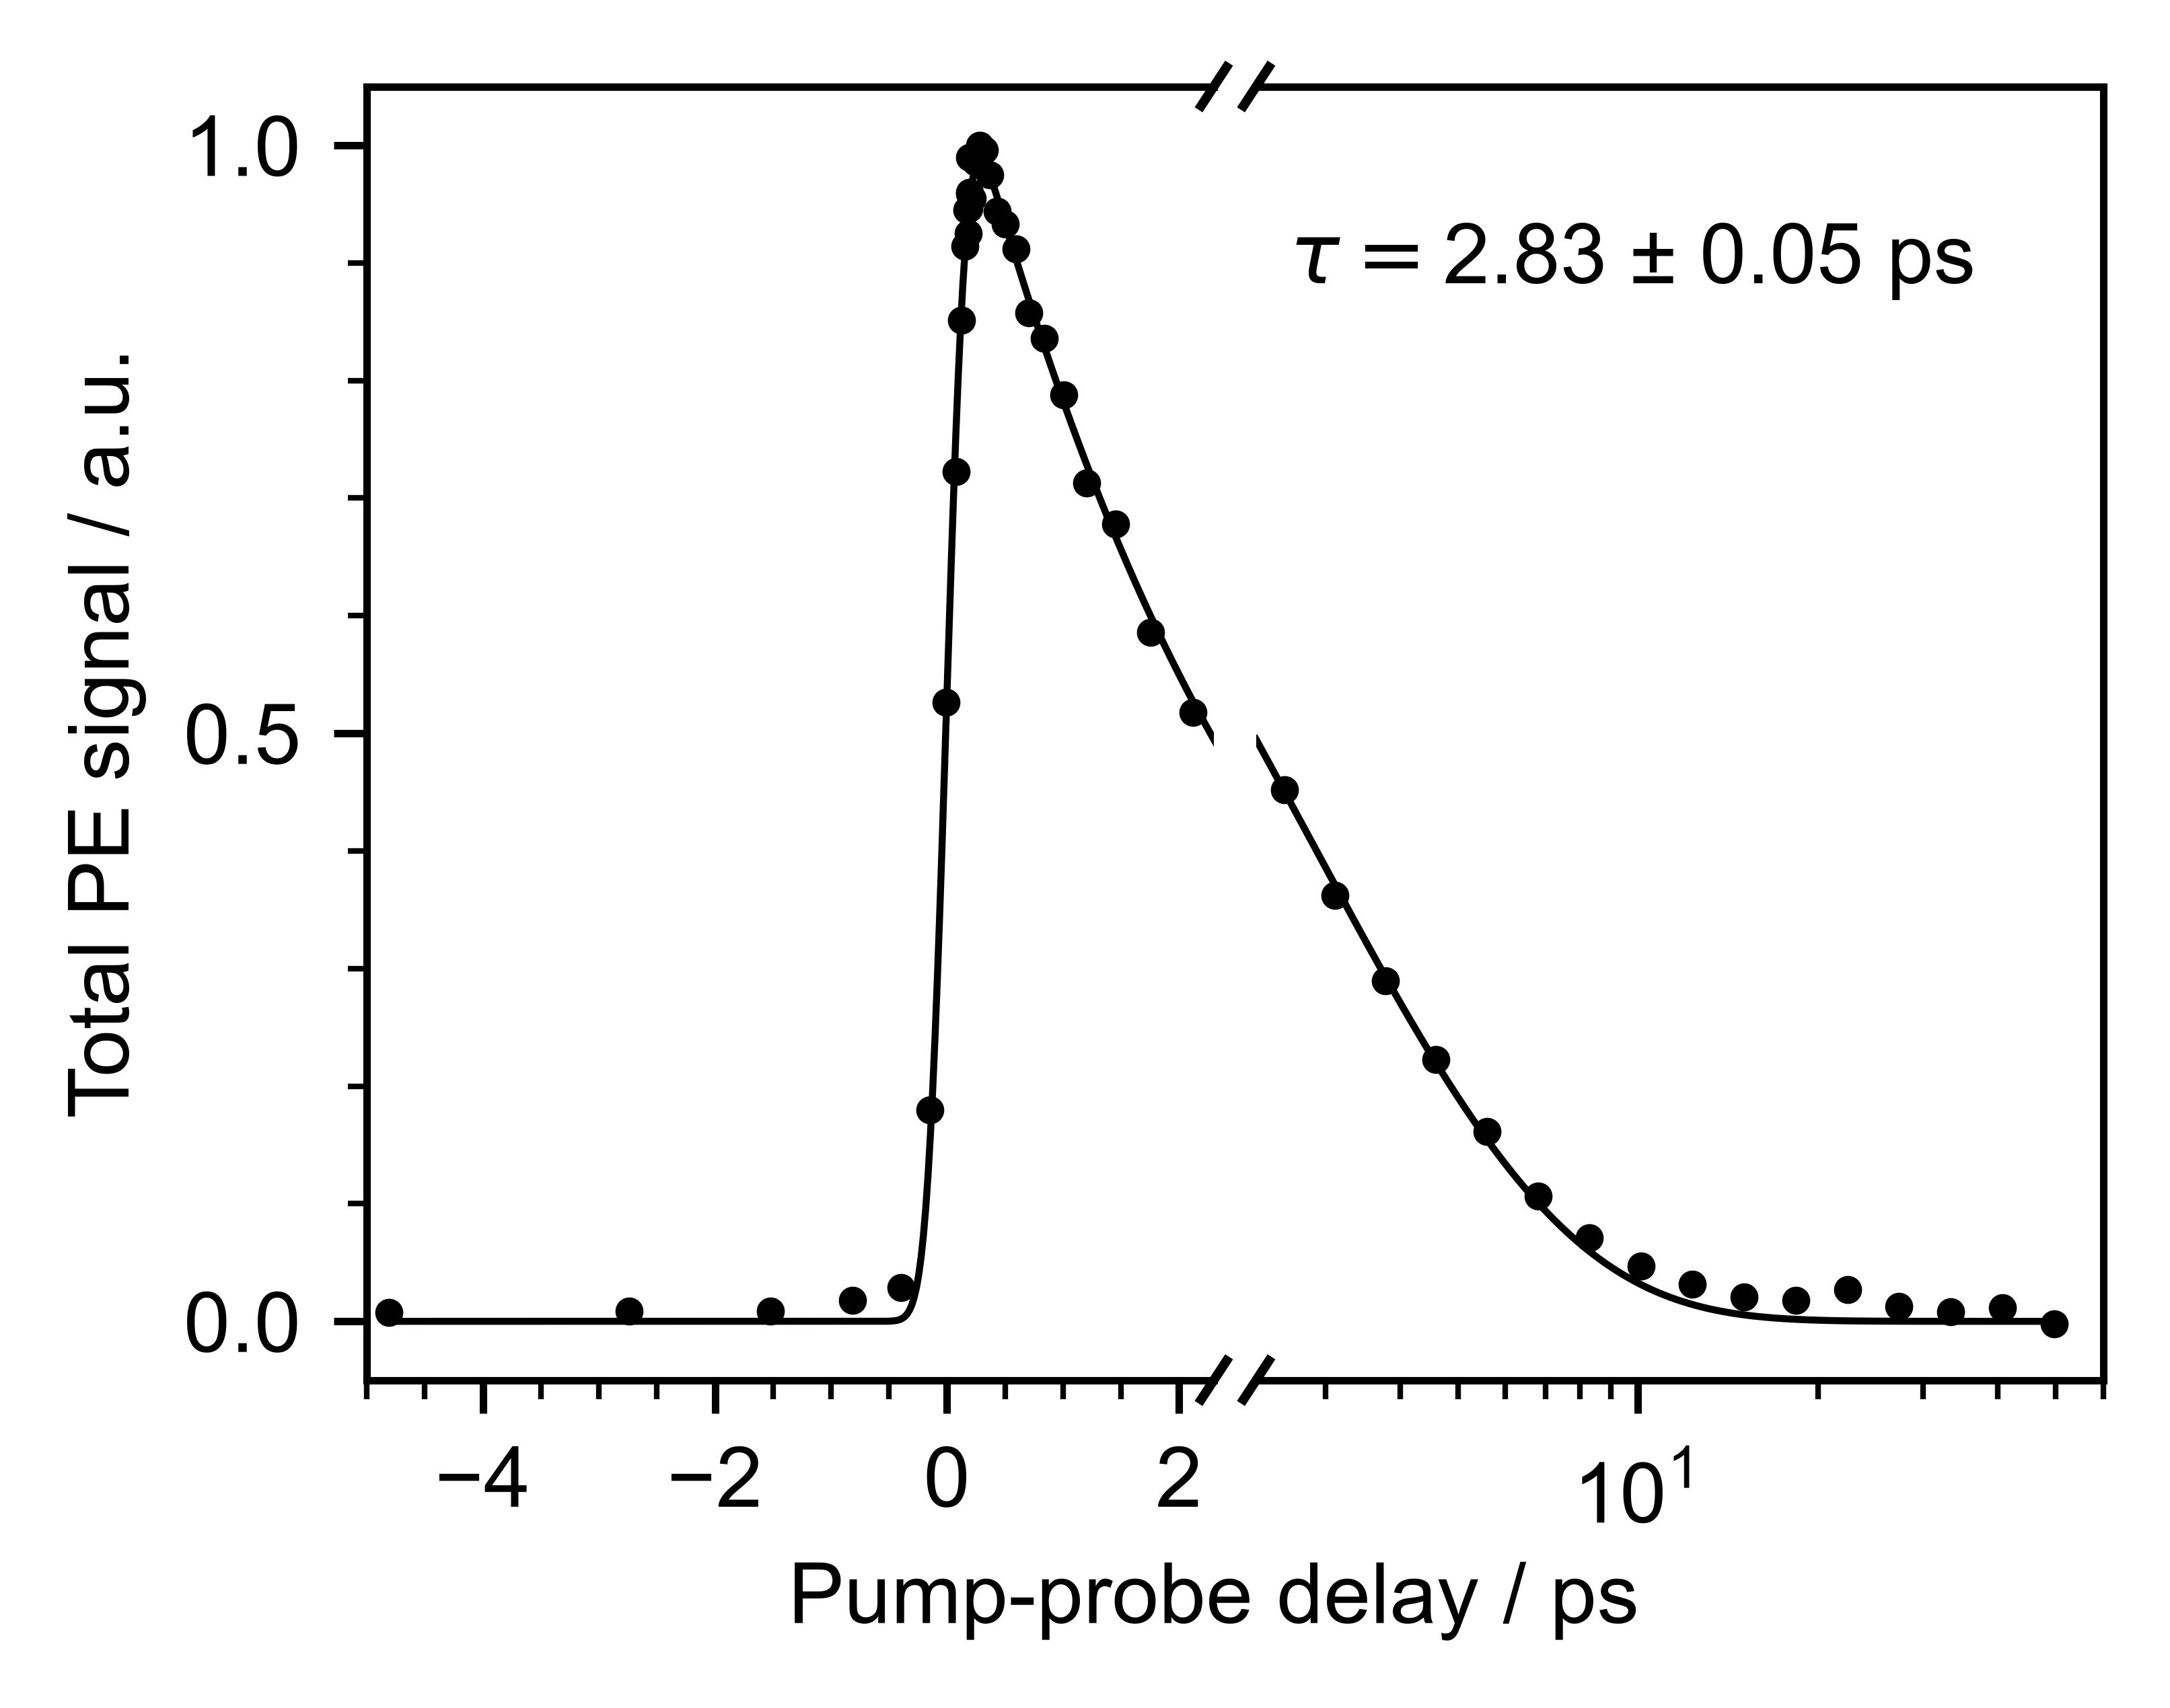

In [8]:
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
# fig.set_size_inches(15.5/2.5/2.54,13.5/2.54/2.5)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)


for ax in axes:
    ax.plot(delays-t0,trace,'ko',ms=2,zorder=100)
    ax.plot(ts-t0,fit_func(ts,*params),'k',lw=.75)

print("A1, tau1, t0")
print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perr])
ax0.set_xlim(-5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

for ax in axes:
    ax.set_ylim(-.05,1.05)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

ax1.text(.85,.9,f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',va='top',transform=ax.transAxes)
   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(2))
ax0.xaxis.set_minor_locator(MultipleLocator(.5))
ax1.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)      # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

In [9]:

fit_func = (lambda x,A1,tau1,A2,tau2,t0: 
            tran.monoexponential_witht0(x,A1,tau1,t0,SIGMA) +
            tran.monoexponential_witht0(x,A2,tau2,t0,SIGMA))

params,pcov=curve_fit(fit_func,delays,trace,
                  p0=[0.101, 0.443, 0.495, 3.047,0.066])
perr = np.sqrt(np.diag(pcov))

print(params)

t0 = params[0]

[ 5.44270847e-01  2.67167616e+00  1.52569966e-02  3.15422728e+01
 -1.94386044e-01]


c:\Users\edoar\OneDrive\Documents\Backup 19-04-20\GitHub\TRPESanalysis\delayscan\analysis.py:9: RuntimeWarning: overflow encountered in exp
  return (A1 * np.exp((-1/tau1)*(x-t0))*np.exp((sigma**2)/(2*(tau1**2))) *


A1, tau1, A2, tau2,t0
[0.544, 2.672, 0.015, 31.542, -0.194]
[0.009, 0.084, 0.01, 32.246, 0.003]


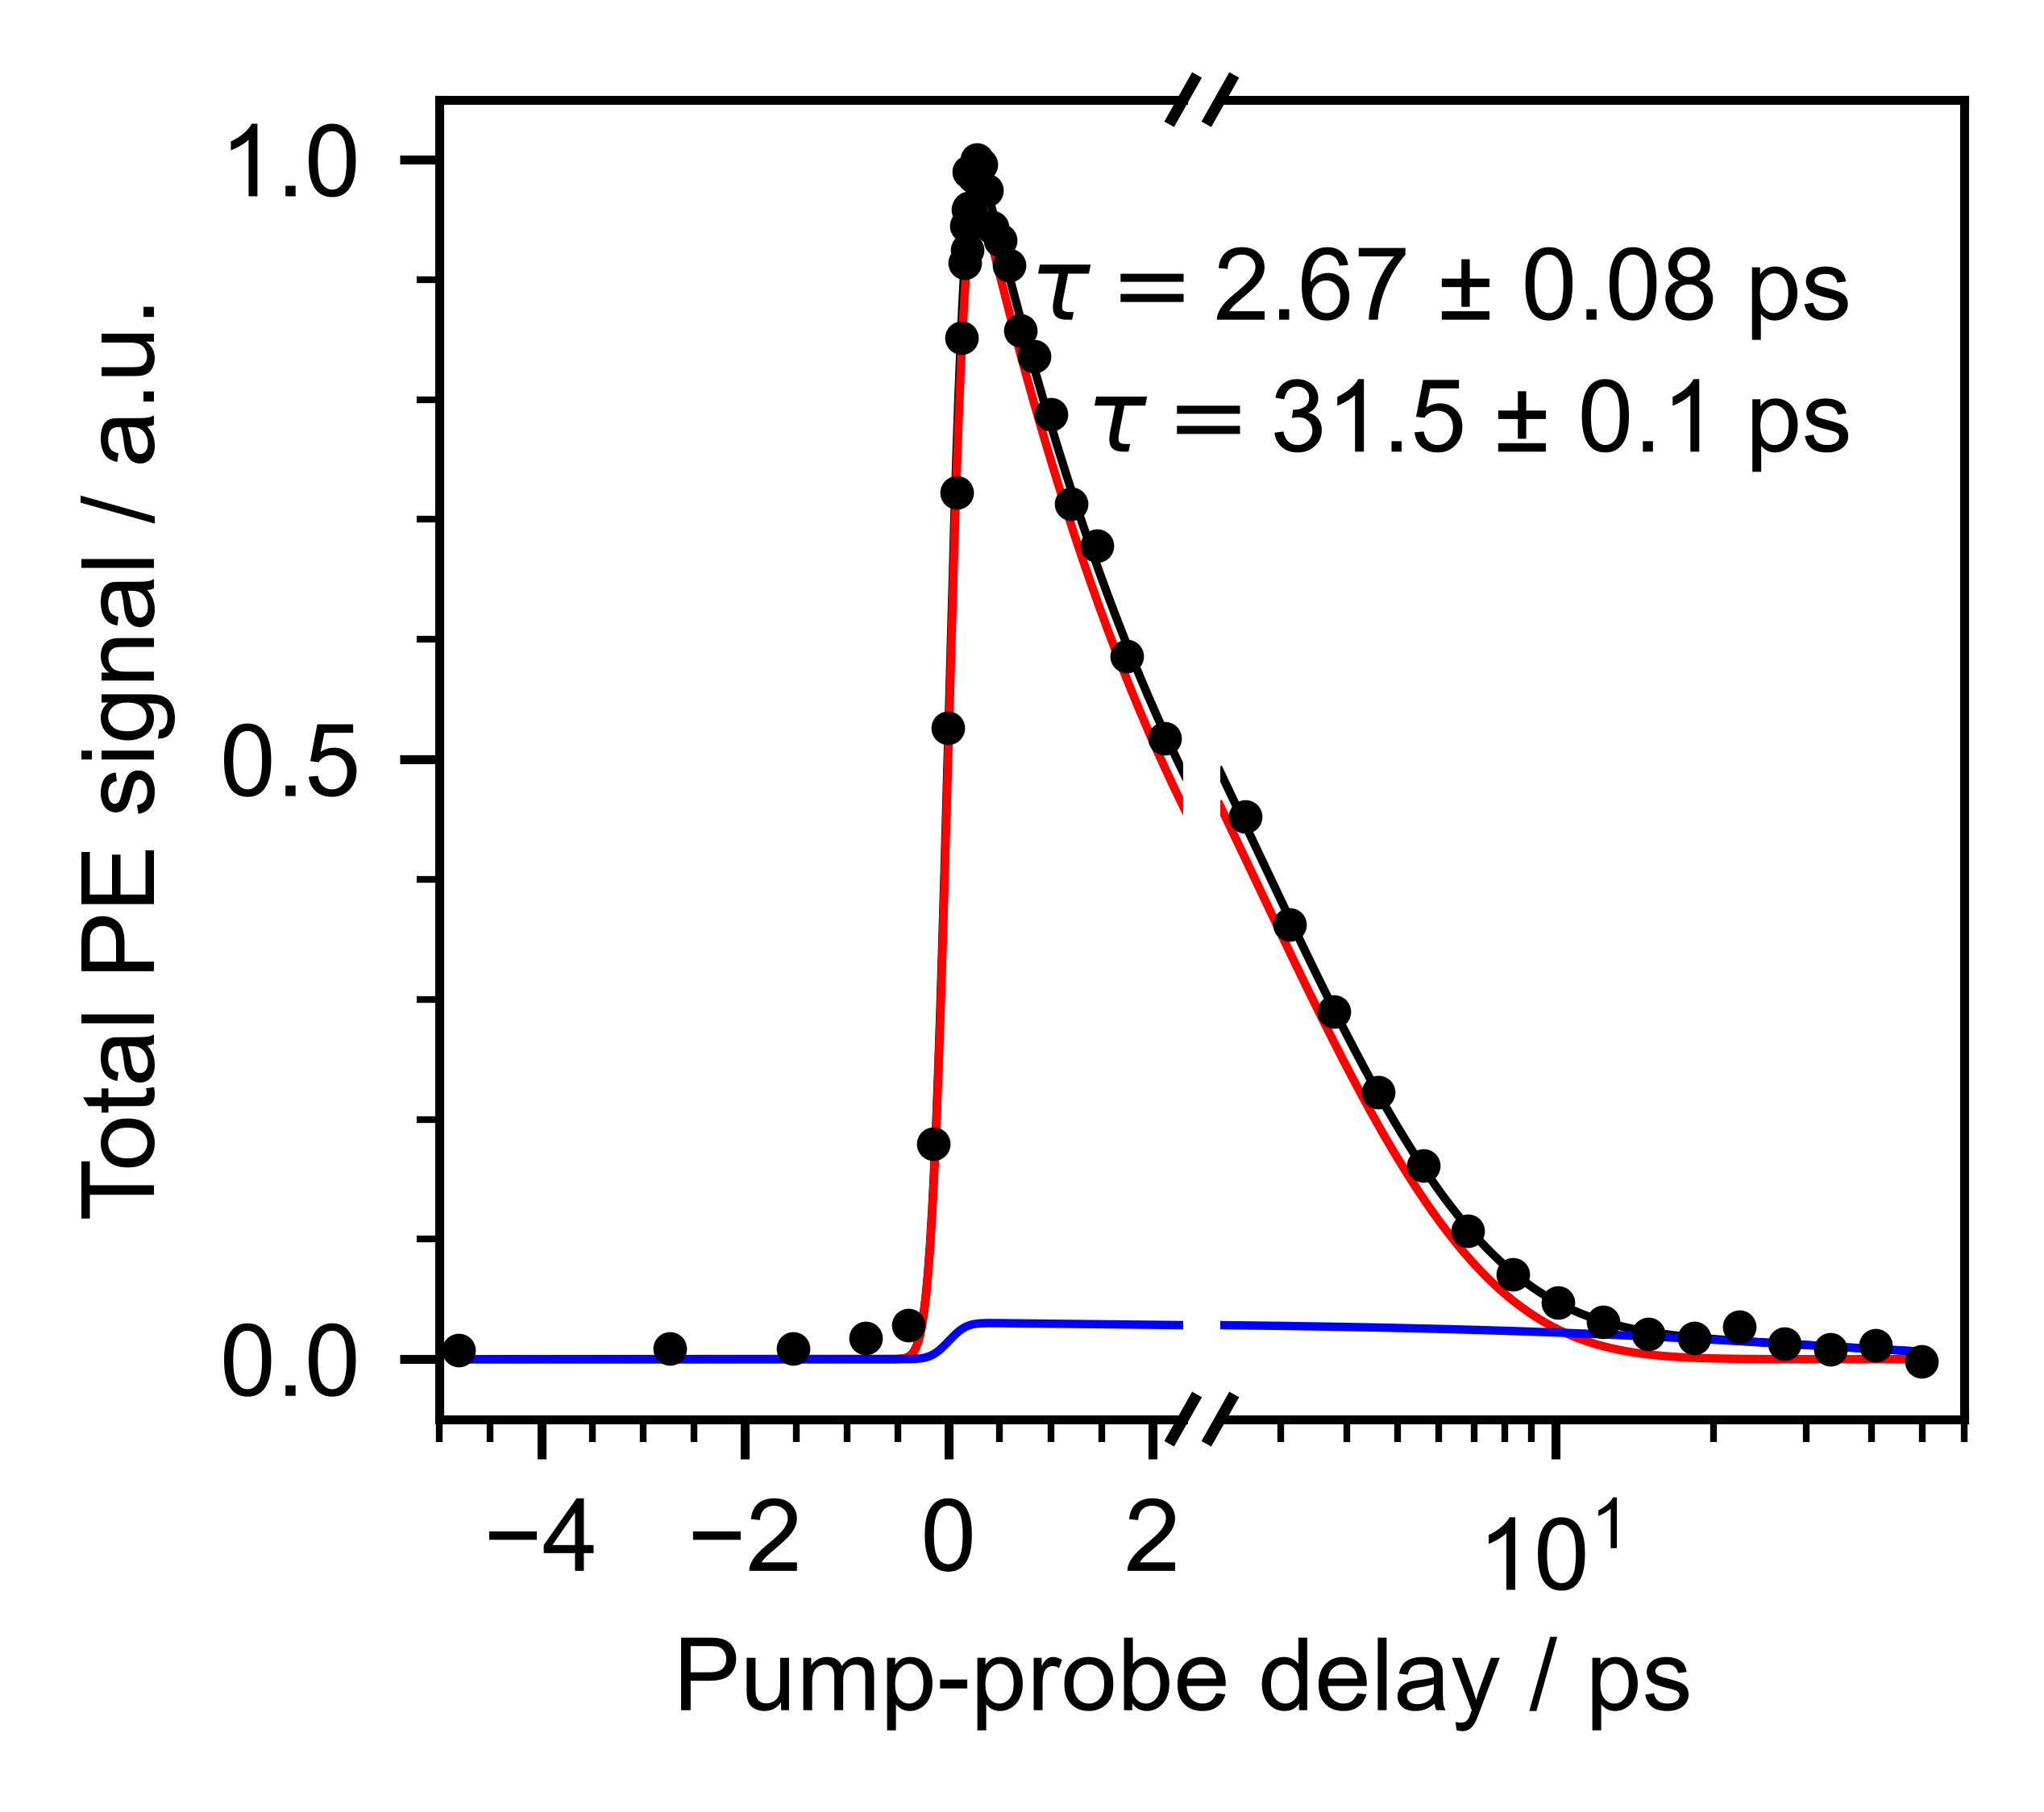

In [10]:
## biexponential
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.54/2.5)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)


t0 = params[-1]

for ax in axes:
    ax.plot(delays-t0,trace,'ko',ms=2,zorder=100)
    ax.plot(ts-t0,fit_func(ts,*params),'k',lw=.75)
    ax.plot(ts-t0,tran.monoexponential_witht0(ts,*params[:2],t0,SIGMA),'r',lw=.75)
    ax.plot(ts-t0,tran.monoexponential_witht0(ts,*params[2:4],t0,SIGMA),'b',lw=.75)
    
print("A1, tau1, A2, tau2,t0")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax0.set_xlim(-5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

for ax in axes:
    ax.set_ylim(-.05,1.05)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

ax1.text(.85,.75,f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',transform=ax.transAxes)
ax1.text(.85,.65,f"$\\tau =${params[3]:.1f} ± {perr[1]:.1f} ps\n",ha='right',transform=ax.transAxes)
   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(2))
ax0.xaxis.set_minor_locator(MultipleLocator(.5))
ax1.xaxis.set_minor_formatter(NullFormatter())


# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

In [14]:
# Save with t0 as 0 ps
savepath = r"data/out/"
save_arr = tr.create_save_arr(scanSet.energies_rebinned,
                              scanSet.delays-scanSet.t0,
                              scanSet.subtracted_rebinned)

np.savetxt(savepath+"SubtractedSpectra.csv",save_arr,delimiter=',', fmt = "%.10e")